# Trabalho Prático de Deep Learning — Frente 3.1: Multilayer Perceptrons
## Previsão de execução financeira de emendas parlamentares a partir de características orçamentárias e municipais

**Disciplina:** Deep Learning — Especialização em IA Aplicada (IFG)

**Problema:** classificação binária. Para cada emenda parlamentar destinada a um município (unidade de observação = registro emenda × município × classificação orçamentária), prever se ela **teve execução financeira** (houve pagamento ou inscrição em restos a pagar) ou **não teve execução** (valor pago e restos a pagar inscritos iguais a zero).

**Utilidade:** antecipar quais emendas têm maior risco de não serem executadas, apoiando o acompanhamento por gestores municipais, órgãos de controle e pela sociedade.

**Fontes:** Portal da Transparência (Emendas Parlamentares, CGU) cruzado com indicadores municipais do IBGE (Cidades@). O tratamento inicial (filtragem 2025/2026, remoção de colunas, tipos) foi feito no notebook `Dataset_final_Emendas_Parlamentares + Cidades IBGE.ipynb`; este notebook parte do CSV resultante.

Estrutura:
1. Configuração e carga
2. Variável alvo e análise exploratória
3. Seleção de atributos e prevenção de vazamento
4. Divisão treino / validação / teste por município
5. Pré-processamento (pipeline ajustado só no treino)
6. Modelos de referência
7. Infraestrutura da MLP
8. Experimento 0 — variantes de pré-processamento
9. Experimento 1 — busca de hiperparâmetros com Optuna
10. Experimento 2 — largura × profundidade
11. Experimento 3 — estratégias de regularização
12. Experimento 4 — três arquiteturas promissoras (várias sementes)
13. Avaliação final no teste, limiar e custos
14. Análises complementares (sensibilidade à divisão, erros por grupo, importância)

## 1. Configuração e carga

In [1]:
import os, time, json, math, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers
import optuna

from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, roc_curve)

SEED = 42
N_TRIALS = int(os.environ.get("N_TRIALS", 40))      # tentativas do Optuna
MAX_EPOCHS = 150                                       # teto de épocas (com parada antecipada)
DATA_PATH = os.environ.get("DATA_PATH", "EmendasParlamentares_DatasetLimpo_-_v3.csv")
FIG_DIR, RES_DIR = "figs", "resultados"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_inter_op_parallelism_threads(2)
except Exception:
    pass

# paleta e estilo dos gráficos
C_AZUL, C_LARANJA, C_VERDE, C_CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5,
                     "figure.facecolor": "white", "axes.facecolor": "white"})
def salvar(fig, nome):
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/{nome}.png", bbox_inches="tight"); plt.show()

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| Optuna", optuna.__version__)

I0000 00:00:1791909362.568991     518 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791909364.206884     518 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | Optuna 5.0.0


In [2]:
COD_COLS = ["Código Função", "Código Subfunção", "Código Programa", "Código Ação",
            "Código Plano Orçamentário", "Código UF IBGE"]
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig", low_memory=False,
                 dtype={c: str for c in COD_COLS})
# Restos a pagar veio como texto com vírgula decimal
df["Valor Restos A Pagar Inscritos"] = pd.to_numeric(
    df["Valor Restos A Pagar Inscritos"].astype(str).str.replace(".", "", regex=False)
      .str.replace(",", ".", regex=False), errors="coerce")
print(df.shape)
df.head(3).T

(36229, 38)


,0,1,2
Tipo de Emenda,Emenda Individual - Transferências com Finalid...,Emenda Individual - Transferências com Finalid...,Emenda Individual - Transferências com Finalid...
Código UF IBGE,3500000,1200000,2400000
Região,Sudeste,Norte,Nordeste
Código Função,20,10,15
Código Subfunção,608,122,451
Código Programa,2014,2015,2054
Código Ação,20ZV,4525,1D73
Código Plano Orçamentário,0000,0000,0000
Valor Pago,97500.0,0.0,0.0
Valor Restos A Pagar Inscritos,0.0,0.0,0.0


## 2. Variável alvo e análise exploratória

**Definição do alvo.** `executada = 1` se `Valor Pago > 0` **ou** `Valor Restos A Pagar Inscritos > 0`; caso contrário `0`.
A inscrição em restos a pagar indica que o recurso foi empenhado e reconhecido como obrigação, ou seja, a emenda avançou na execução mesmo sem pagamento no exercício. Considerar só o `Valor Pago` classificaria como "não executadas" emendas que estão em fase final de execução.

As duas colunas usadas para construir o alvo são **removidas** das entradas.

,proporção
Valor Pago > 0,32.68%
Restos a Pagar > 0,18.95%
ambos > 0,3.33%
alvo = 1 (executada),48.30%


Valores negativos de restos a pagar (estornos): 2


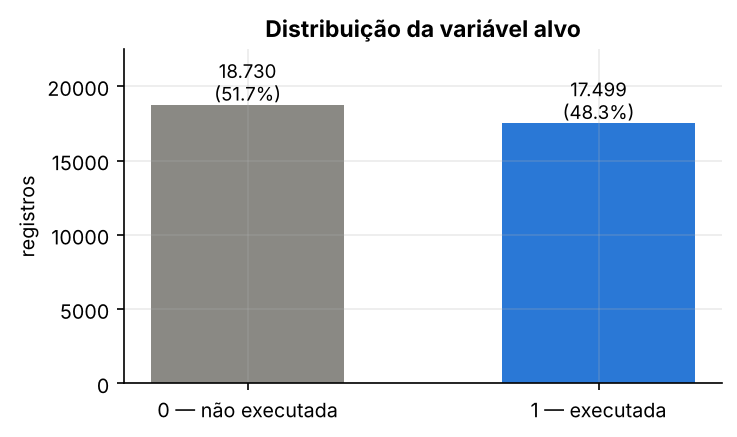

In [3]:
vp, rap = df["Valor Pago"], df["Valor Restos A Pagar Inscritos"]
df["executada"] = ((vp > 0) | (rap > 0)).astype(int)
y_all = df["executada"].values

resumo_alvo = pd.DataFrame({
    "proporção": [(vp > 0).mean(), (rap > 0).mean(), ((vp > 0) & (rap > 0)).mean(), df["executada"].mean()]},
    index=["Valor Pago > 0", "Restos a Pagar > 0", "ambos > 0", "alvo = 1 (executada)"])
display(resumo_alvo.style.format("{:.2%}"))
print("Valores negativos de restos a pagar (estornos):", (rap < 0).sum())

fig, ax = plt.subplots(figsize=(5, 3))
cont = df["executada"].value_counts().sort_index()
ax.bar(["0 — não executada", "1 — executada"], cont.values, color=[C_CINZA, C_AZUL], width=0.55)
for i, v in enumerate(cont.values):
    ax.text(i, v, f"{v:,}\n({v/len(df):.1%})".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("registros"); ax.set_title("Distribuição da variável alvo"); ax.set_ylim(0, cont.max()*1.2)
salvar(fig, "01_alvo")

As classes estão praticamente balanceadas (≈52% / 48%). Ainda assim, usamos **Macro-F1** como métrica principal, pois ela pesa igualmente o desempenho nas duas classes, e reportamos acurácia, precisão, revocação, AUC-ROC e matriz de confusão como complementares.

### 2.1 Tipos, ausentes, duplicados

In [4]:
NUM_COLS = [c for c in df.select_dtypes(include="number").columns
            if c not in ["Valor Pago", "Valor Restos A Pagar Inscritos", "executada", "codigo_ibge"]]
CAT_COLS = ["Tipo de Emenda", "Região", "bioma", "sistema_costeiro_marinho", "Código UF IBGE",
            "Código Função", "Código Subfunção", "Código Programa", "Código Ação", "Código Plano Orçamentário"]
print(f"{len(NUM_COLS)} numéricas, {len(CAT_COLS)} categóricas")

aus = df[NUM_COLS + CAT_COLS].isna().sum()
display(aus[aus > 0].to_frame("ausentes").assign(pct=lambda d: (d.ausentes/len(df)).map("{:.2%}".format)))
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("Municípios distintos:", df["codigo_ibge"].nunique())
display(df[CAT_COLS].nunique().to_frame("categorias distintas"))

25 numéricas, 10 categóricas


,ausentes,pct
despesas_brutas_empenhadas,41,0.11%
docentes_ensino_medio,19,0.05%
esgotamento_sanitario_adequado,68,0.19%
estabelecimentos_ensino_medio,19,0.05%
estabelecimentos_saude_sus,21,0.06%
matriculas_ensino_medio,19,0.05%
populacao_renda_per_capita_maior_meio_salario,21,0.06%
receitas_brutas_realizadas,41,0.11%
transferencias_correntes,41,0.11%
urbanizacao_vias_publicas,21,0.06%


Linhas duplicadas (todas as colunas): 2014
Municípios distintos: 5416


,categorias distintas
Tipo de Emenda,5
Região,5
bioma,6
sistema_costeiro_marinho,2
Código UF IBGE,27
Código Função,25
Código Subfunção,64
Código Programa,149
Código Ação,313
Código Plano Orçamentário,25


* Ausentes são raros (< 0,2% em qualquer coluna) e concentrados em municípios sem dado no IBGE → imputação pela **mediana do treino** (numéricas) e **moda do treino** (categóricas).
* Os ~2.000 registros duplicados correspondem a emendas distintas com a mesma classificação orçamentária para o mesmo município (o dataset não traz identificador da emenda após a limpeza). São mantidos; como a divisão é por município, duplicatas nunca ficam em partições diferentes.
* `Código Ação` (313) e `Código Programa` (149) têm alta cardinalidade → one-hot com agrupamento de categorias raras (`min_frequency=10`).

### 2.2 Estatísticas descritivas e distribuições das numéricas

In [5]:
desc = df[NUM_COLS].describe().T
desc["assimetria"] = df[NUM_COLS].skew()
desc["assimetria_log1p"] = np.log1p(df[NUM_COLS].clip(lower=0)).skew()
display(desc[["mean", "std", "min", "50%", "max", "assimetria", "assimetria_log1p"]].round(2))

,mean,std,min,50%,max,assimetria,assimetria_log1p
arborizacao_vias_publicas,6.596000e+01,2.115000e+01,0.43,6.815000e+01,1.000000e+02,-0.52,-1.89
area_km2,2.244180e+03,6.808220e+03,3.38,5.709400e+02,1.595333e+05,8.99,0.54
area_urbanizada_km2,4.295000e+01,1.182500e+02,0.22,8.010000e+00,9.110800e+02,5.37,0.84
densidade_demografica,6.037700e+02,1.701910e+03,0.15,4.200000e+01,1.341681e+04,4.02,0.69
despesas_brutas_empenhadas,2.632361e+09,1.290707e+10,3293552.19,1.786453e+08,1.235718e+11,8.07,1.16
docentes_ensino_fundamental,2.042380e+03,7.855170e+03,10.00,2.350000e+02,7.027400e+04,6.98,0.84
docentes_ensino_medio,8.359300e+02,3.122740e+03,4.00,8.600000e+01,2.612300e+04,6.40,0.88
esgotamento_sanitario_adequado,4.650000e+01,3.436000e+01,0.02,4.800000e+01,9.995000e+01,0.01,-0.96
estabelecimentos_ensino_fundamental,1.208400e+02,3.873800e+02,1.00,2.200000e+01,2.967000e+03,5.78,0.79
estabelecimentos_ensino_medio,4.145000e+01,1.555300e+02,1.00,5.000000e+00,1.334000e+03,6.60,1.24


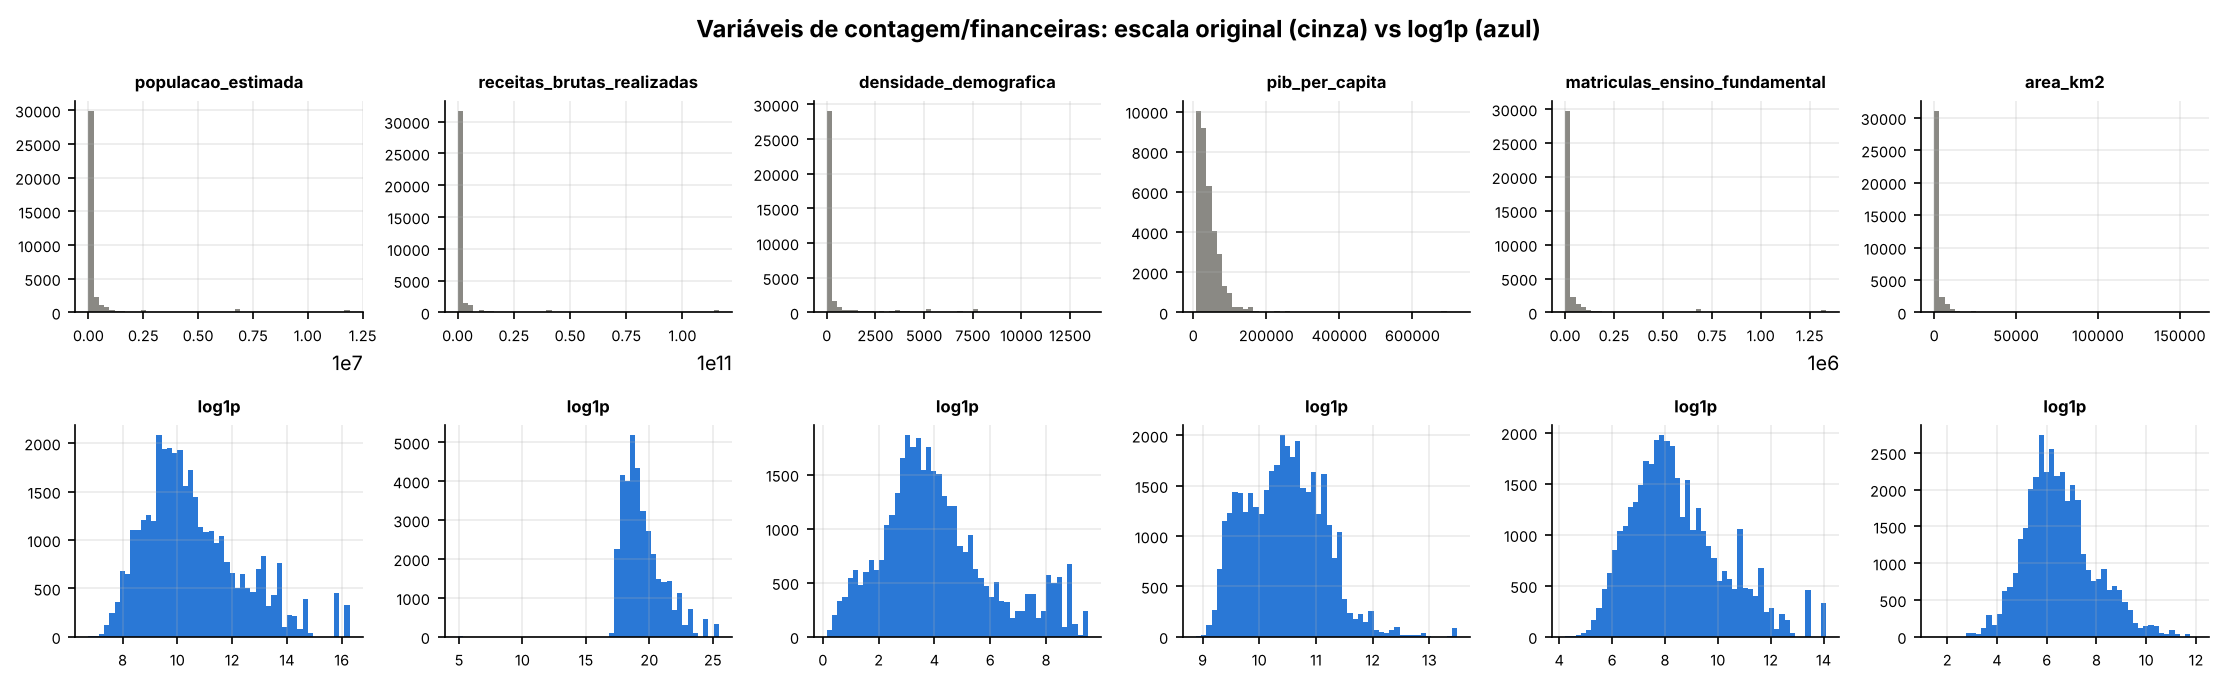

In [6]:
vars_plot = ["populacao_estimada", "receitas_brutas_realizadas", "densidade_demografica",
             "pib_per_capita", "matriculas_ensino_fundamental", "area_km2"]
fig, axes = plt.subplots(2, 6, figsize=(15, 4.6))
for j, c in enumerate(vars_plot):
    axes[0, j].hist(df[c].dropna(), bins=50, color=C_CINZA); axes[0, j].set_title(c, fontsize=8)
    axes[1, j].hist(np.log1p(df[c].dropna()), bins=50, color=C_AZUL); axes[1, j].set_title("log1p", fontsize=8)
    for a in axes[:, j]: a.tick_params(labelsize=7)
fig.suptitle("Variáveis de contagem/financeiras: escala original (cinza) vs log1p (azul)", fontweight="bold")
salvar(fig, "02_distribuicoes_log")

Variáveis de contagem, população, área e valores financeiros têm assimetria extrema (cauda longa dominada por capitais: São Paulo, Rio de Janeiro). Aplicamos **log1p antes da padronização** às variáveis não negativas cuja assimetria cai substancialmente após o log. Indicadores percentuais (escolarização, esgotamento, arborização, urbanização) e `transferencias_correntes` apenas são padronizados.

In [7]:
# Valores potencialmente anômalos (regra 1.5*IQR) e casos suspeitos
iqr_out = {}
for c in NUM_COLS:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    iqr_out[c] = ((df[c] < q1 - 1.5*i) | (df[c] > q3 + 1.5*i)).mean()
display(pd.Series(iqr_out, name="fração fora de 1.5·IQR").sort_values(ascending=False).head(10).map("{:.1%}".format))
print("transferencias_correntes > 100%:", (df["transferencias_correntes"] > 100).sum(), "registros")
print("populacao_ocupada > 100%:", (df["populacao_ocupada"] > 100).sum(), "registros")
print("corr(populacao_censo, populacao_estimada) =", round(df["populacao_censo"].corr(df["populacao_estimada"]), 4))

densidade_demografica            16.9%
pessoal_ocupado                  16.6%
populacao_estimada               16.4%
populacao_censo                  16.3%
matriculas_ensino_fundamental    16.3%
docentes_ensino_fundamental      16.3%
despesas_brutas_empenhadas       16.1%
matriculas_ensino_medio          15.9%
receitas_brutas_realizadas       15.9%
estabelecimentos_ensino_medio    15.6%
Name: fração fora de 1.5·IQR, dtype: str

transferencias_correntes > 100%: 4 registros
populacao_ocupada > 100%: 18 registros
corr(populacao_censo, populacao_estimada) = 0.9998


Os "outliers" pela regra do IQR são em sua maioria **valores legítimos** (municípios grandes), por isso não são removidos — o log1p reduz sua influência. Percentuais acima de 100% (`transferencias_correntes`, `populacao_ocupada`) são raros e provêm da própria fonte (p. ex. pessoal ocupado inclui trabalhadores de outros municípios); são mantidos e registrados como limitação.

### 2.3 Relação do alvo com as categorias e com o município

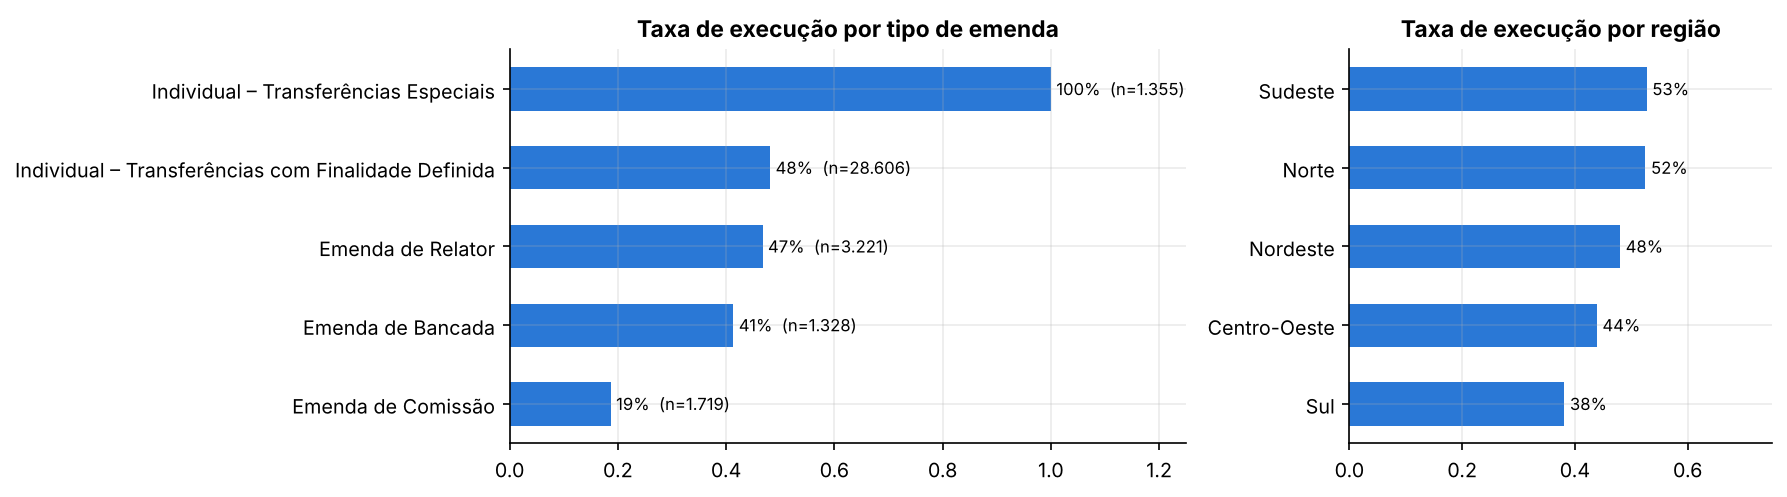

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
t = df.groupby("Tipo de Emenda")["executada"].agg(["mean", "size"]).sort_values("mean")
axes[0].barh([s.replace("Emenda Individual - ", "Individual – ") for s in t.index], t["mean"], color=C_AZUL, height=0.55)
for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
    axes[0].text(m + .01, i, f"{m:.0%}  (n={n:,})".replace(",", "."), va="center", fontsize=8)
axes[0].set_xlim(0, 1.25); axes[0].set_title("Taxa de execução por tipo de emenda")
r = df.groupby("Região")["executada"].mean().sort_values()
axes[1].barh(r.index, r.values, color=C_AZUL, height=0.55)
for i, m in enumerate(r.values): axes[1].text(m + .01, i, f"{m:.0%}", va="center", fontsize=8)
axes[1].set_xlim(0, 0.75); axes[1].set_title("Taxa de execução por região")
salvar(fig, "03_alvo_por_categoria")

count    5416.0
mean        6.7
std        12.3
min         1.0
25%         3.0
50%         4.0
75%         7.0
max       456.0
Name: size, dtype: float64


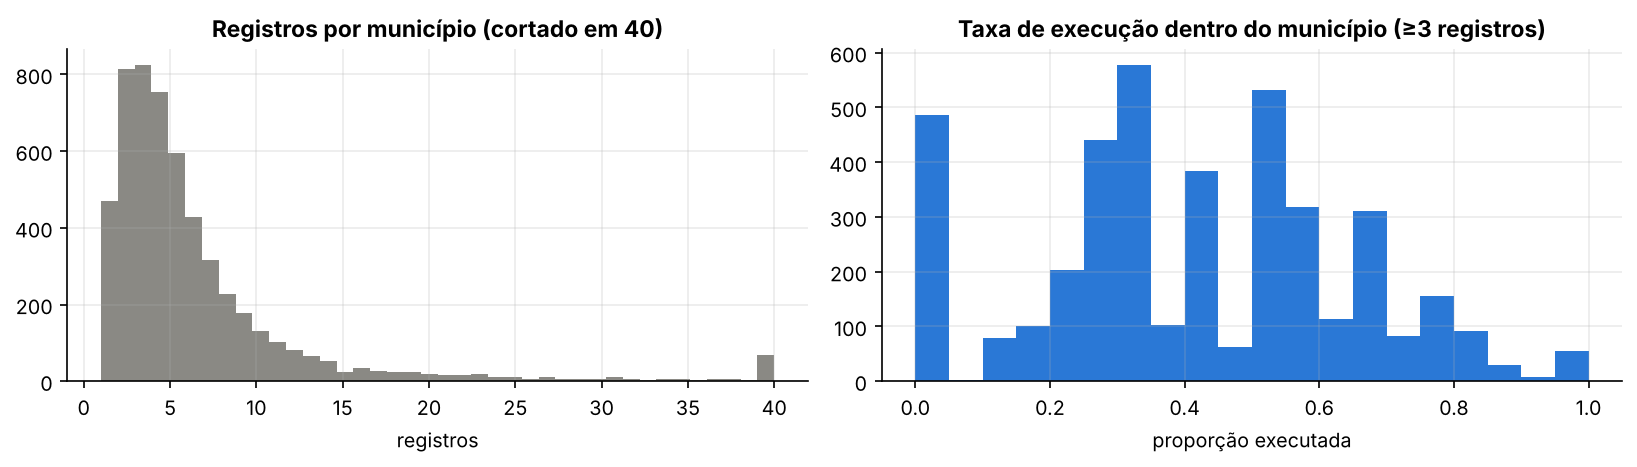

In [9]:
por_mun = df.groupby("codigo_ibge")["executada"].agg(["size", "mean"])
print(por_mun["size"].describe().round(1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(por_mun["size"].clip(upper=40), bins=40, color=C_CINZA)
axes[0].set_title("Registros por município (cortado em 40)"); axes[0].set_xlabel("registros")
axes[1].hist(por_mun.loc[por_mun["size"] >= 3, "mean"], bins=20, color=C_AZUL)
axes[1].set_title("Taxa de execução dentro do município (≥3 registros)"); axes[1].set_xlabel("proporção executada")
salvar(fig, "04_municipios")

* As emendas de **Transferência Especial** ("emendas PIX") são executadas em 100% dos casos — característica institucional dessa modalidade (repasse direto, sem convênio). É um sinal legítimo, conhecido no momento da emenda, e não vazamento.
* Emendas de **Comissão** têm a menor taxa de execução (≈19%).
* Cada município aparece em média em ~6,7 registros (até 456 no Rio de Janeiro). **Como os 30 atributos municipais se repetem em todos os registros de um município, uma divisão aleatória permitiria que o modelo "reconhecesse" o município no teste.** Por isso a divisão é feita **por município** (seção 4). A taxa de execução varia bastante dentro de cada município, o que indica que as características da emenda também importam.

## 3. Seleção de atributos e prevenção de vazamento

| Coluna | Decisão | Justificativa |
|---|---|---|
| `Valor Pago`, `Valor Restos A Pagar Inscritos` | removidas | definem o alvo |
| `Valor Empenhado`, `Valor Liquidado`, RAP pagos/cancelados | já removidas no tratamento | etapas da execução — vazamento direto |
| `Ano da Emenda`, códigos/nomes do autor, nomes de função/ação etc. | já removidas | identificadores ou redundantes com os códigos |
| `codigo_ibge` | não entra como preditor | usado **somente** para agrupar a divisão por município |
| `mortalidade_infantil`, colunas `*_ano` | já removidas | inconsistências / metadados |
| códigos orçamentários, UF, região, bioma, tipo | categóricas (one-hot) | códigos numéricos não têm relação de ordem |
| 26 indicadores municipais | numéricas (log1p quando assimétricas + padronização) | perfil socioeconômico e fiscal do destino |

In [10]:
LOG_COLS = [c for c in NUM_COLS if df[c].min() >= 0 and desc.loc[c, "assimetria"] > 2
            and abs(desc.loc[c, "assimetria_log1p"]) < abs(desc.loc[c, "assimetria"]) / 2]
STD_COLS = [c for c in NUM_COLS if c not in LOG_COLS]
print("log1p + padronização:", LOG_COLS)
print("só padronização:", STD_COLS)

X_all = df[NUM_COLS + CAT_COLS].copy()
grupos = df["codigo_ibge"].values

log1p + padronização: ['area_km2', 'area_urbanizada_km2', 'densidade_demografica', 'despesas_brutas_empenhadas', 'docentes_ensino_fundamental', 'docentes_ensino_medio', 'estabelecimentos_ensino_fundamental', 'estabelecimentos_ensino_medio', 'estabelecimentos_saude_sus', 'internacoes_diarreia_sus_100mil', 'matriculas_ensino_fundamental', 'matriculas_ensino_medio', 'pessoal_ocupado', 'pib_per_capita', 'populacao_censo', 'populacao_estimada', 'receitas_brutas_realizadas', 'rendimento_medio_sal_min']
só padronização: ['arborizacao_vias_publicas', 'esgotamento_sanitario_adequado', 'populacao_ocupada', 'populacao_renda_per_capita_maior_meio_salario', 'taxa_escolarizacao_6_14', 'transferencias_correntes', 'urbanizacao_vias_publicas']


## 4. Divisão treino / validação / teste agrupada por município

Usamos `StratifiedGroupKFold`: nenhum município aparece em mais de uma partição e a proporção de classes é aproximadamente preservada. Primeiro separamos 1/7 dos municípios para **teste** (~14%) e, do restante, 1/6 para **validação** (~14%), resultando em ≈72/14/14.

In [11]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
idx_trval, idx_te = next(sgkf.split(X_all, y_all, grupos))
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
rel_tr, rel_va = next(sgkf2.split(X_all.iloc[idx_trval], y_all[idx_trval], grupos[idx_trval]))
idx_tr, idx_va = idx_trval[rel_tr], idx_trval[rel_va]

Xtr_raw, Xva_raw, Xte_raw = X_all.iloc[idx_tr], X_all.iloc[idx_va], X_all.iloc[idx_te]
ytr, yva, yte = y_all[idx_tr], y_all[idx_va], y_all[idx_te]

g_tr, g_va, g_te = set(grupos[idx_tr]), set(grupos[idx_va]), set(grupos[idx_te])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te)
divisao = pd.DataFrame({"registros": [len(idx_tr), len(idx_va), len(idx_te)],
                        "municípios": [len(g_tr), len(g_va), len(g_te)],
                        "% executada": [ytr.mean(), yva.mean(), yte.mean()]},
                       index=["treino", "validação", "teste"])
divisao["% registros"] = divisao["registros"] / len(df)
display(divisao.style.format({"% executada": "{:.1%}", "% registros": "{:.1%}"}))
divisao.to_csv(f"{RES_DIR}/divisao.csv")

,registros,municípios,% executada,% registros
treino,25867,3875,48.3%,71.4%
validação,5175,749,48.3%,14.3%
teste,5187,792,48.3%,14.3%


## 5. Pré-processamento

Pipeline `ColumnTransformer` **ajustado somente no treino** (medianas, médias/desvios, categorias e frequências) e aplicado a validação e teste:
* numéricas assimétricas: mediana → `log1p` → `StandardScaler`
* demais numéricas: mediana → `StandardScaler`
* categóricas: moda → `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)` — categorias com menos de 10 ocorrências no treino e categorias novas vão para uma coluna "infrequente".

In [12]:
def make_preproc(variante="log+std"):
    escalador = RobustScaler() if variante.endswith("robust") else StandardScaler()
    if variante.startswith("log"):
        num = [("log", Pipeline([("imp", SimpleImputer(strategy="median")),
                                 ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                 ("sc", escalador)]), LOG_COLS),
               ("std", Pipeline([("imp", SimpleImputer(strategy="median")),
                                 ("sc", RobustScaler() if variante.endswith("robust") else StandardScaler())]), STD_COLS)]
    else:
        num = [("std", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", escalador)]), NUM_COLS)]
    cat = [("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                             ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                                   sparse_output=False))]), CAT_COLS)]
    return ColumnTransformer(num + cat)

def transformar(variante="log+std"):
    pp = make_preproc(variante).fit(Xtr_raw)
    f = lambda X: pp.transform(X).astype("float32")
    return pp, f(Xtr_raw), f(Xva_raw), f(Xte_raw)

preproc, Xtr, Xva, Xte = transformar("log+std")
N_FEAT = Xtr.shape[1]
print("Dimensão de entrada da rede:", N_FEAT)
ohe = preproc.named_transformers_["cat"].named_steps["ohe"]
print({c: len(cats) for c, cats in zip(CAT_COLS, ohe.categories_)})
print("colunas one-hot após agrupamento de raras:", N_FEAT - len(NUM_COLS))

Dimensão de entrada da rede: 313
{'Tipo de Emenda': 5, 'Região': 5, 'bioma': 6, 'sistema_costeiro_marinho': 2, 'Código UF IBGE': 26, 'Código Função': 24, 'Código Subfunção': 62, 'Código Programa': 133, 'Código Ação': 259, 'Código Plano Orçamentário': 23}
colunas one-hot após agrupamento de raras: 288


## 6. Métricas e modelos de referência

In [13]:
def metricas(y, p, limiar=0.5):
    yhat = (p >= limiar).astype(int)
    return {"macro_f1": f1_score(y, yhat, average="macro"), "acuracia": accuracy_score(y, yhat),
            "precisao": precision_score(y, yhat, zero_division=0), "revocacao": recall_score(y, yhat),
            "f1_classe1": f1_score(y, yhat), "auc": roc_auc_score(y, p),
            "log_loss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7))}

ref_modelos = {
    "Classe majoritária": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(max_iter=3000, C=1.0),
    "Gradient boosting (HGB)": HistGradientBoostingClassifier(random_state=SEED),
}
ref_res, ref_fit = [], {}
for nome, m in ref_modelos.items():
    t0 = time.perf_counter(); m.fit(Xtr, ytr); t_tr = time.perf_counter() - t0
    ref_fit[nome] = m
    for part, X, y in [("treino", Xtr, ytr), ("validação", Xva, yva)]:
        p = m.predict_proba(X)[:, 1]
        ref_res.append({"modelo": nome, "partição": part, "tempo_treino_s": t_tr, **metricas(y, p)})
ref_res = pd.DataFrame(ref_res)
display(ref_res.round(4))
ref_res.to_csv(f"{RES_DIR}/referencias_val.csv", index=False)

,modelo,partição,tempo_treino_s,macro_f1,acuracia,precisao,revocacao,f1_classe1,auc,log_loss
0,Classe majoritária,treino,0.0013,0.3408,0.5170,0.0000,0.0000,0.0000,0.5000,7.7846
1,Classe majoritária,validação,0.0013,0.3408,0.5169,0.0000,0.0000,0.0000,0.5000,7.7865
2,Regressão logística,treino,3.4893,0.8884,0.8885,0.8777,0.8936,0.8856,0.9570,0.2684
3,Regressão logística,validação,3.4893,0.8701,0.8701,0.8570,0.8776,0.8672,0.9457,0.2967
4,Gradient boosting (HGB),treino,3.7943,0.9126,0.9127,0.9007,0.9207,0.9106,0.9760,0.2073
5,Gradient boosting (HGB),validação,3.7943,0.8761,0.8761,0.8635,0.8832,0.8732,0.9571,0.2616


A regressão logística é o modelo linear de referência (equivalente a uma rede sem camadas ocultas). O gradient boosting é uma referência forte para dados tabulares, útil para situar a MLP. A classe majoritária mostra o piso (Macro-F1 ≈ 0,34).

## 7. Infraestrutura da MLP (Keras)

* Camadas ocultas `Dense` com ativação configurável; formato **constante** (todas com `units` neurônios) ou **funil** (metade a cada camada, mínimo 8).
* Saída: 1 neurônio com **sigmoide** e perda **entropia cruzada binária** (classificação binária).
* Regularização opcional: dropout após cada camada oculta, penalidades L1/L2 nos pesos, Batch Normalization antes da ativação, parada antecipada (`EarlyStopping` na perda de validação com `restore_best_weights`).
* Otimizador Adam.

In [14]:
def construir_mlp(n_in, n_layers=2, units=128, shape="constante", activation="relu",
                  dropout=0.0, l1=0.0, l2=0.0, batchnorm=False, lr=1e-3, **_):
    reg = keras.regularizers.L1L2(l1=l1, l2=l2) if (l1 or l2) else None
    inp = keras.Input(shape=(n_in,)); x = inp
    for i in range(n_layers):
        u = units if shape == "constante" else max(8, units // (2 ** i))
        x = layers.Dense(u, kernel_regularizer=reg, use_bias=not batchnorm)(x)
        if batchnorm: x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        if dropout > 0: x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    modelo = keras.Model(inp, out)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy")
    return modelo

class MacroF1Callback(keras.callbacks.Callback):
    """Calcula Macro-F1 (limiar 0,5) no treino e na validação a cada época; opcionalmente reporta ao Optuna."""
    def __init__(self, Xtr, ytr, Xva, yva, trial=None, n_tr=6000):
        super().__init__()
        rng = np.random.default_rng(0); s = rng.choice(len(Xtr), min(n_tr, len(Xtr)), replace=False)
        self.Xtr, self.ytr, self.Xva, self.yva, self.trial = Xtr[s], ytr[s], Xva, yva, trial
        self.hist = {"f1_tr": [], "f1_va": []}
    def on_epoch_end(self, epoch, logs=None):
        p_tr = self.model.predict(self.Xtr, batch_size=4096, verbose=0).ravel()
        p_va = self.model.predict(self.Xva, batch_size=4096, verbose=0).ravel()
        f_tr = f1_score(self.ytr, (p_tr >= .5).astype(int), average="macro")
        f_va = f1_score(self.yva, (p_va >= .5).astype(int), average="macro")
        self.hist["f1_tr"].append(f_tr); self.hist["f1_va"].append(f_va)
        if self.trial is not None:
            self.trial.report(f_va, epoch)
            if self.trial.should_prune():
                self.model.stop_training = True; self.podado = True

def treinar(cfg, Xtr_, ytr_, Xva_, yva_, seed=SEED, max_epochs=MAX_EPOCHS,
            early_stop=True, trial=None, acompanhar_f1=True):
    keras.backend.clear_session(); keras.utils.set_random_seed(seed)
    modelo = construir_mlp(Xtr_.shape[1], **cfg)
    cbs = []
    f1cb = MacroF1Callback(Xtr_, ytr_, Xva_, yva_, trial=trial) if acompanhar_f1 else None
    if f1cb: cbs.append(f1cb)
    if early_stop:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg.get("patience", 10),
                                                 restore_best_weights=True))
    t0 = time.perf_counter()
    h = modelo.fit(Xtr_, ytr_, validation_data=(Xva_, yva_), epochs=max_epochs,
                   batch_size=cfg.get("batch_size", 256), verbose=0, callbacks=cbs, shuffle=True)
    t_treino = time.perf_counter() - t0
    hist = dict(h.history)
    if f1cb: hist.update(f1cb.hist)
    info = {"tempo_treino_s": t_treino, "epocas": len(hist["loss"]),
            "melhor_epoca": int(np.argmin(hist["val_loss"])) + 1,
            "n_params": modelo.count_params(), "podado": getattr(f1cb, "podado", False)}
    return modelo, hist, info

def prever(modelo, X):
    t0 = time.perf_counter(); p = modelo.predict(X, batch_size=4096, verbose=0).ravel()
    return p, (time.perf_counter() - t0) / len(X) * 1e6   # µs por amostra

def avaliar(modelo, info, nome, extra=None):
    p_tr, _ = prever(modelo, Xtr); p_va, t_inf = prever(modelo, Xva)
    mt, mv = metricas(ytr, p_tr), metricas(yva, p_va)
    linha = {"config": nome, **(extra or {}), **{f"val_{k}": v for k, v in mv.items()},
             "treino_macro_f1": mt["macro_f1"], "treino_log_loss": mt["log_loss"],
             "gap_f1": mt["macro_f1"] - mv["macro_f1"], "inferencia_us_amostra": t_inf, **info}
    return linha, p_va

# teste rápido de tempo
_m, _h, _i = treinar({"n_layers": 2, "units": 128, "lr": 1e-3, "batch_size": 256}, Xtr, ytr, Xva, yva, max_epochs=3)
print(_i)

{'tempo_treino_s': 2.985989150000023, 'epocas': 3, 'melhor_epoca': 3, 'n_params': 56833, 'podado': False}


## 8. Experimento 0 — variantes de pré-processamento

Antes da busca, verificamos experimentalmente a recomendação de usar log1p e comparamos `StandardScaler` com `RobustScaler`, mantendo uma MLP fixa (2×128, ReLU, Adam 1e-3, lote 256, parada antecipada) e 3 sementes.

In [15]:
cfg_fixa = {"n_layers": 2, "units": 128, "lr": 1e-3, "batch_size": 256, "patience": 10}
res_pp = []
for var in ["std", "log+std", "log+robust"]:
    _, A, B, _C = transformar(var)
    for s in range(3):
        m, h, info = treinar(cfg_fixa, A, ytr, B, yva, seed=SEED + s, acompanhar_f1=False)
        p, _ = prever(m, B)
        res_pp.append({"variante": var, "semente": s, **metricas(yva, p), "epocas": info["epocas"]})
res_pp = pd.DataFrame(res_pp)
tab_pp = res_pp.groupby("variante")[["macro_f1", "auc", "log_loss", "epocas"]].agg(["mean", "std"]).round(4)
display(tab_pp); res_pp.to_csv(f"{RES_DIR}/exp0_preprocessamento.csv", index=False)

macro_f1             auc         log_loss           epocas        
               mean     std    mean     std     mean     std     mean     std
variante                                                                     
log+robust   0.8827  0.0021  0.9582  0.0009   0.2676  0.0012  15.3333  1.1547
log+std      0.8803  0.0031  0.9574  0.0020   0.2683  0.0049  15.3333  2.0817
std          0.8834  0.0061  0.9580  0.0018   0.2668  0.0060  15.6667  1.1547

## 9. Experimento 1 — busca de hiperparâmetros com Optuna

**Métrica otimizada:** Macro-F1 na **validação** (limiar 0,5) — o teste não é usado.
**Amostrador:** TPE (bayesiano), semente fixa. **Poda:** `MedianPruner` — interrompe tentativas cuja Macro-F1 de validação na época *t* fica abaixo da mediana das anteriores (após 8 tentativas completas e 10 épocas de aquecimento), economizando tempo.

| Hiperparâmetro | Espaço | Justificativa |
|---|---|---|
| `n_layers` | 1–5 | profundidade: de rede rasa a profunda para dados tabulares |
| `units` | {32, 64, 128, 256, 512} | largura da 1ª camada, escala log2 |
| `shape` | constante / funil | distribuição de neurônios entre camadas |
| `activation` | ReLU / ELU | ELU evita neurônios "mortos" |
| `dropout` | 0–0,5 | regularização estocástica; acima de 0,5 tende a subajuste |
| `l2` | 1e-6–1e-2 (log) | penalidade nos pesos; escala log cobre de quase nula a forte |
| `batchnorm` | sim / não | estabiliza o treino de redes mais profundas |
| `lr` | 1e-4–1e-2 (log) | hiperparâmetro de maior impacto no Adam |
| `batch_size` | {64, 128, 256, 512} | ruído do gradiente × custo por época |
| `patience` | {5, 10, 20} | critério de parada antecipada |

Fixos (baixo impacto esperado ou exigência do problema): otimizador Adam, saída sigmoide, perda BCE, teto de 150 épocas.

In [16]:
def espaco(trial):
    return {"n_layers": trial.suggest_int("n_layers", 1, 5),
            "units": trial.suggest_categorical("units", [32, 64, 128, 256, 512]),
            "shape": trial.suggest_categorical("shape", ["constante", "funil"]),
            "activation": trial.suggest_categorical("activation", ["relu", "elu"]),
            "dropout": trial.suggest_float("dropout", 0.0, 0.5),
            "l2": trial.suggest_float("l2", 1e-6, 1e-2, log=True),
            "batchnorm": trial.suggest_categorical("batchnorm", [False, True]),
            "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
            "batch_size": trial.suggest_categorical("batch_size", [64, 128, 256, 512]),
            "patience": trial.suggest_categorical("patience", [5, 10, 20])}

def objetivo(trial):
    cfg = espaco(trial)
    m, h, info = treinar(cfg, Xtr, ytr, Xva, yva, trial=trial)
    p_va, _ = prever(m, Xva)
    mv = metricas(yva, p_va)
    for k, v in {**info, "val_auc": mv["auc"], "val_log_loss": mv["log_loss"],
                 "treino_f1_final": h["f1_tr"][-1]}.items():
        trial.set_user_attr(k, float(v) if not isinstance(v, bool) else v)
    if info["podado"]:
        raise optuna.TrialPruned()
    return mv["macro_f1"]

optuna.logging.set_verbosity(optuna.logging.WARNING)
estudo = optuna.create_study(direction="maximize", study_name="mlp_emendas",
                             sampler=optuna.samplers.TPESampler(seed=SEED),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=10))
t0 = time.perf_counter()
estudo.optimize(objetivo, n_trials=N_TRIALS, show_progress_bar=False)
t_busca = time.perf_counter() - t0
print(f"Busca: {N_TRIALS} tentativas em {t_busca/60:.1f} min")
print("Melhor Macro-F1 (val):", round(estudo.best_value, 4)); print(estudo.best_params)

Busca: 40 tentativas em 25.1 min
Melhor Macro-F1 (val): 0.8873
{'n_layers': 2, 'units': 32, 'shape': 'constante', 'activation': 'relu', 'dropout': 0.2611160690210018, 'l2': 2.381895375882678e-05, 'batchnorm': True, 'lr': 0.0023513644034690584, 'batch_size': 512, 'patience': 20}


In [17]:
tent = estudo.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
tent.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in tent.columns]
tent.to_csv(f"{RES_DIR}/exp1_optuna_tentativas.csv", index=False)
completas = tent[tent.state == "COMPLETE"].sort_values("value", ascending=False)
print("completas:", len(completas), "| podadas:", (tent.state == "PRUNED").sum())
display(completas.head(10)[["number", "value", "val_auc", "n_layers", "units", "shape", "activation", "dropout",
                            "l2", "batchnorm", "lr", "batch_size", "patience", "n_params", "epocas", "tempo_treino_s"]].round(4))
try:
    imp = optuna.importance.get_param_importances(estudo)
    display(pd.Series(imp, name="importância (fANOVA)").round(3))
    pd.Series(imp).to_csv(f"{RES_DIR}/exp1_importancia_hp.csv")
except Exception as e:
    imp = {}; print("importância indisponível:", e)

completas: 26 | podadas: 14


,number,value,val_auc,n_layers,units,shape,activation,dropout,l2,batchnorm,lr,batch_size,patience,n_params,epocas,tempo_treino_s
30,30,0.8873,0.9610,2,32,constante,relu,0.2611,0.0000,True,0.0024,512,20,11329.0,32.0,19.5107
36,36,0.8861,0.9611,2,32,constante,relu,0.2650,0.0000,True,0.0030,128,20,11329.0,30.0,31.4463
2,2,0.8857,0.9602,2,32,constante,relu,0.2989,0.0049,True,0.0001,512,20,11329.0,150.0,74.1048
22,22,0.8854,0.9606,2,32,constante,relu,0.2470,0.0000,True,0.0046,128,20,11329.0,28.0,26.3104
39,39,0.8839,0.9592,1,32,constante,relu,0.1817,0.0000,True,0.0031,64,20,10177.0,26.0,33.6358
3,3,0.8839,0.9586,1,128,funil,elu,0.3856,0.0000,False,0.0053,64,10,40321.0,25.0,31.0630
26,26,0.8833,0.9615,3,32,constante,relu,0.2840,0.0000,False,0.0060,128,20,12193.0,30.0,27.2708
28,28,0.8828,0.9607,1,32,constante,relu,0.3780,0.0000,True,0.0016,512,20,10177.0,39.0,19.6107
15,15,0.8828,0.9601,2,32,constante,relu,0.2536,0.0000,True,0.0008,128,20,11329.0,30.0,24.9440
33,33,0.8827,0.9608,1,32,constante,relu,0.3283,0.0000,True,0.0032,128,20,10177.0,29.0,25.8180


dropout       0.645
n_layers      0.128
l2            0.124
batch_size    0.057
lr            0.019
batchnorm     0.013
units         0.011
shape         0.001
patience      0.001
activation    0.000
Name: importância (fANOVA), dtype: float64

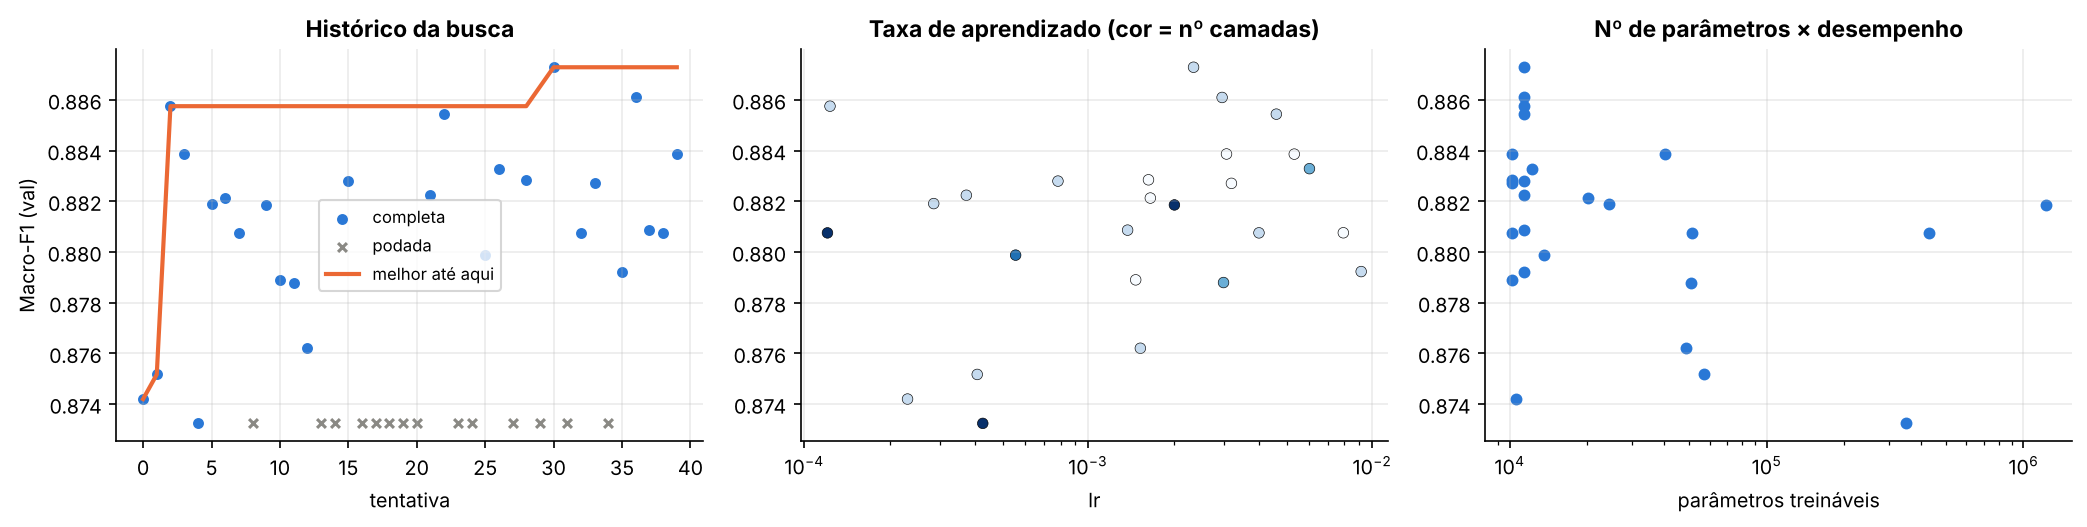

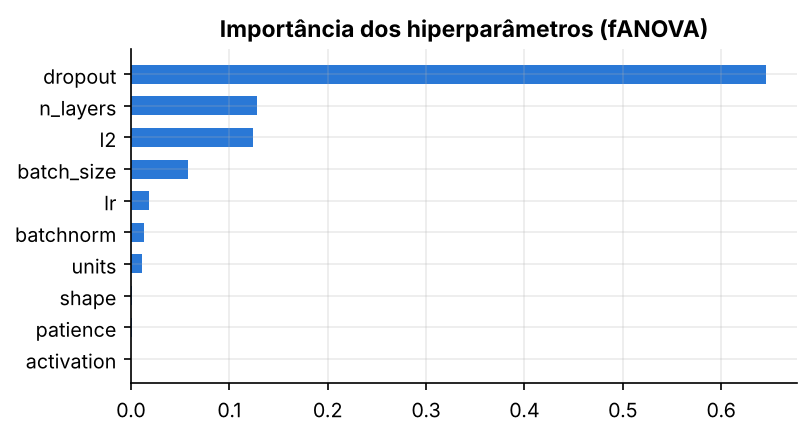

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ok = tent[tent.state == "COMPLETE"]
axes[0].scatter(ok["number"], ok["value"], s=18, color=C_AZUL, label="completa")
pr = tent[tent.state == "PRUNED"]; axes[0].scatter(pr["number"], [ok["value"].min()]*len(pr), marker="x", s=18, color=C_CINZA, label="podada")
axes[0].plot(ok["number"], ok["value"].cummax(), color=C_LARANJA, lw=2, label="melhor até aqui")
axes[0].set_title("Histórico da busca"); axes[0].set_xlabel("tentativa"); axes[0].set_ylabel("Macro-F1 (val)"); axes[0].legend(fontsize=8)
axes[1].scatter(ok["lr"], ok["value"], c=ok["n_layers"], cmap="Blues", s=26, edgecolor="k", linewidth=.3)
axes[1].set_xscale("log"); axes[1].set_title("Taxa de aprendizado (cor = nº camadas)"); axes[1].set_xlabel("lr")
axes[2].scatter(ok["n_params"], ok["value"], s=22, color=C_AZUL)
axes[2].set_xscale("log"); axes[2].set_title("Nº de parâmetros × desempenho"); axes[2].set_xlabel("parâmetros treináveis")
salvar(fig, "05_optuna")
if imp:
    fig, ax = plt.subplots(figsize=(5.5, 3))
    s = pd.Series(imp).sort_values(); ax.barh(s.index, s.values, color=C_AZUL, height=.6)
    ax.set_title("Importância dos hiperparâmetros (fANOVA)"); salvar(fig, "06_importancia_hp")

## 10. Experimento 2 — largura × profundidade (capacidade)

Para isolar o efeito da capacidade, treinamos redes **sem regularização e sem parada antecipada** (60 épocas), com a taxa de aprendizado e o lote da melhor tentativa do Optuna, variando profundidade (1–4 camadas) e largura (16–512 neurônios, formato constante). Registramos a melhor Macro-F1 de validação, a Macro-F1 ao final das 60 épocas, o *gap* treino−validação e o custo.

In [19]:
melhor = estudo.best_params
lr_b, bs_b = melhor["lr"], melhor["batch_size"]
EP_CAP = 60
res_cap, hist_cap = [], {}
for nl in [1, 2, 3, 4]:
    for u in [16, 64, 256, 512]:
        cfg = {"n_layers": nl, "units": u, "lr": lr_b, "batch_size": bs_b}
        m, h, info = treinar(cfg, Xtr, ytr, Xva, yva, max_epochs=EP_CAP, early_stop=False)
        p_va, t_inf = prever(m, Xva)
        res_cap.append({"camadas": nl, "neuronios": u, "n_params": info["n_params"],
                        "val_f1_melhor": max(h["f1_va"]), "epoca_melhor_f1": int(np.argmax(h["f1_va"])) + 1,
                        "val_f1_final": h["f1_va"][-1], "treino_f1_final": h["f1_tr"][-1],
                        "gap_final": h["f1_tr"][-1] - h["f1_va"][-1],
                        "val_loss_min": min(h["val_loss"]), "val_loss_final": h["val_loss"][-1],
                        "tempo_treino_s": info["tempo_treino_s"]})
        hist_cap[(nl, u)] = h
res_cap = pd.DataFrame(res_cap); res_cap.to_csv(f"{RES_DIR}/exp2_largura_profundidade.csv", index=False)
display(res_cap.round(4))

,camadas,neuronios,n_params,val_f1_melhor,epoca_melhor_f1,val_f1_final,treino_f1_final,gap_final,val_loss_min,val_loss_final,tempo_treino_s
0,1,16,5041,0.8850,9,0.8844,0.9069,0.0225,0.2591,0.2692,27.9852
1,1,64,20161,0.8859,10,0.8770,0.9274,0.0504,0.2588,0.2974,28.1948
2,1,256,80641,0.8860,5,0.8812,0.9468,0.0655,0.2603,0.3387,37.1467
3,1,512,161281,0.8842,13,0.8807,0.9560,0.0753,0.2624,0.3833,49.5053
4,2,16,5313,0.8884,14,0.8808,0.9140,0.0332,0.2588,0.2796,27.3525
5,2,64,24321,0.8860,8,0.8784,0.9473,0.0689,0.2677,0.4236,29.7151
6,2,256,146433,0.8846,19,0.8536,0.9520,0.0985,0.2673,0.7733,45.0284
7,2,512,423937,0.8821,13,0.8666,0.9746,0.1080,0.2593,0.9637,71.1918
8,3,16,5585,0.8844,11,0.8798,0.9174,0.0376,0.2689,0.3277,24.4326
9,3,64,28481,0.8858,4,0.8630,0.9535,0.0905,0.2615,0.5969,30.8549


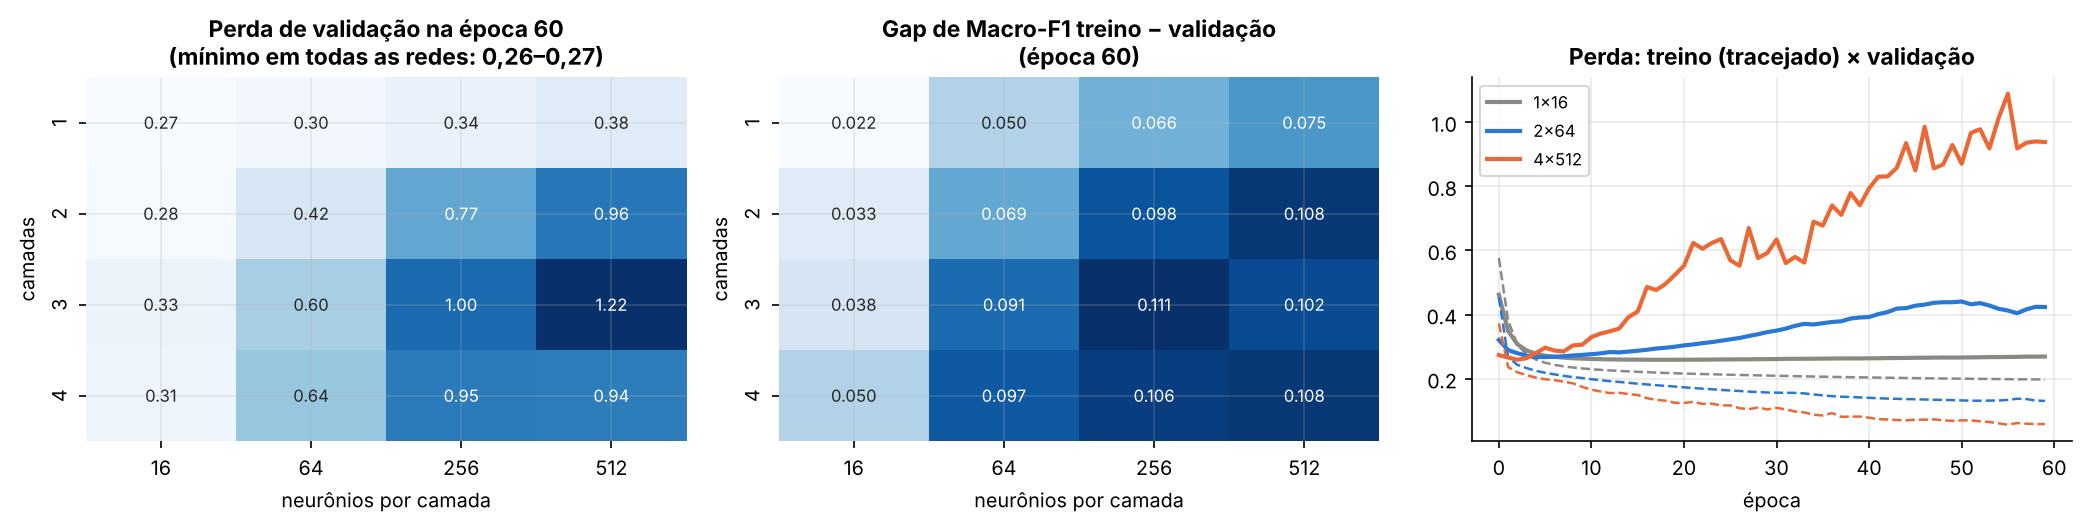

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, tit, fmt in [(axes[0], "val_loss_final", "Perda de validação na época 60\n(mínimo em todas as redes: 0,26–0,27)", ".2f"),
                          (axes[1], "gap_final", "Gap de Macro-F1 treino − validação\n(época 60)", ".3f")]:
    piv = res_cap.pivot(index="camadas", columns="neuronios", values=col)
    sns.heatmap(piv, annot=True, fmt=fmt, cmap="Blues", ax=ax, cbar=False, annot_kws={"fontsize": 8})
    ax.set_title(tit); ax.set_xlabel("neurônios por camada")
for (nl, u), cor in [((1, 16), C_CINZA), ((2, 64), C_AZUL), ((4, 512), C_LARANJA)]:
    h = hist_cap[(nl, u)]
    axes[2].plot(h["loss"], color=cor, lw=1.2, ls="--"); axes[2].plot(h["val_loss"], color=cor, lw=2, label=f"{nl}×{u}")
axes[2].set_title("Perda: treino (tracejado) × validação"); axes[2].set_xlabel("época"); axes[2].legend(fontsize=8)
salvar(fig, "07_capacidade")

## 11. Experimento 3 — estratégias de regularização

Partimos de uma rede de **alta capacidade** (4 camadas × 512, ≈ 1,1 M parâmetros), que no Experimento 2 apresentou overfitting, e comparamos estratégias isoladas e combinadas, todas com 80 épocas e 3 sementes (a parada antecipada, quando usada, restaura os melhores pesos).

In [21]:
base_reg = {"n_layers": 4, "units": 512, "lr": lr_b, "batch_size": bs_b}
estrategias = {
    "nenhuma": ({}, False),
    "parada antecipada": ({"patience": 10}, True),
    "dropout 0,3": ({"dropout": 0.3}, False),
    "dropout 0,5": ({"dropout": 0.5}, False),
    "L2 1e-3": ({"l2": 1e-3}, False),
    "L1 1e-4": ({"l1": 1e-4}, False),
    "BatchNorm": ({"batchnorm": True}, False),
    "dropout 0,3 + L2 1e-4 + BN + parada": ({"dropout": 0.3, "l2": 1e-4, "batchnorm": True, "patience": 10}, True),
}
res_reg, hist_reg = [], {}
for nome, (extra, es) in estrategias.items():
    for s in range(3):
        m, h, info = treinar({**base_reg, **extra}, Xtr, ytr, Xva, yva, seed=SEED + s, max_epochs=80, early_stop=es)
        p_va, _ = prever(m, Xva); mv = metricas(yva, p_va)
        p_tr, _ = prever(m, Xtr); mt = metricas(ytr, p_tr)
        res_reg.append({"estrategia": nome, "semente": s, "val_macro_f1": mv["macro_f1"], "val_auc": mv["auc"],
                        "val_log_loss": mv["log_loss"], "treino_macro_f1": mt["macro_f1"],
                        "gap_f1": mt["macro_f1"] - mv["macro_f1"], "epocas": info["epocas"],
                        "tempo_treino_s": info["tempo_treino_s"]})
        if s == 0: hist_reg[nome] = h
res_reg = pd.DataFrame(res_reg); res_reg.to_csv(f"{RES_DIR}/exp3_regularizacao.csv", index=False)
tab_reg = res_reg.groupby("estrategia", sort=False).agg(
    val_f1=("val_macro_f1", "mean"), val_f1_dp=("val_macro_f1", "std"), val_auc=("val_auc", "mean"),
    val_log_loss=("val_log_loss", "mean"), treino_f1=("treino_macro_f1", "mean"), gap=("gap_f1", "mean"),
    epocas=("epocas", "mean"), tempo_s=("tempo_treino_s", "mean"))
display(tab_reg.round(4)); tab_reg.to_csv(f"{RES_DIR}/exp3_regularizacao_resumo.csv")

,val_f1,val_f1_dp,val_auc,val_log_loss,treino_f1,gap,epocas,tempo_s
estrategia,,,,,,,,
nenhuma,0.8692,0.0021,0.9443,0.8275,0.9743,0.1051,80.0000,170.0322
parada antecipada,0.8798,0.0005,0.9565,0.2669,0.9012,0.0214,12.3333,25.6490
"dropout 0,3",0.8716,0.0025,0.9501,0.4923,0.9648,0.0932,80.0000,190.2912
"dropout 0,5",0.8816,0.0015,0.9542,0.3882,0.9444,0.0629,80.0000,189.8909
L2 1e-3,0.8699,0.0074,0.9492,0.3163,0.9203,0.0504,80.0000,171.2374
L1 1e-4,0.8748,0.0056,0.9510,0.3180,0.9218,0.0471,80.0000,173.2988
BatchNorm,0.8699,0.0066,0.9441,0.7755,0.9710,0.1012,80.0000,192.6065
"dropout 0,3 + L2 1e-4 + BN + parada",0.8829,0.0022,0.9599,0.2600,0.9096,0.0267,24.6667,76.6816


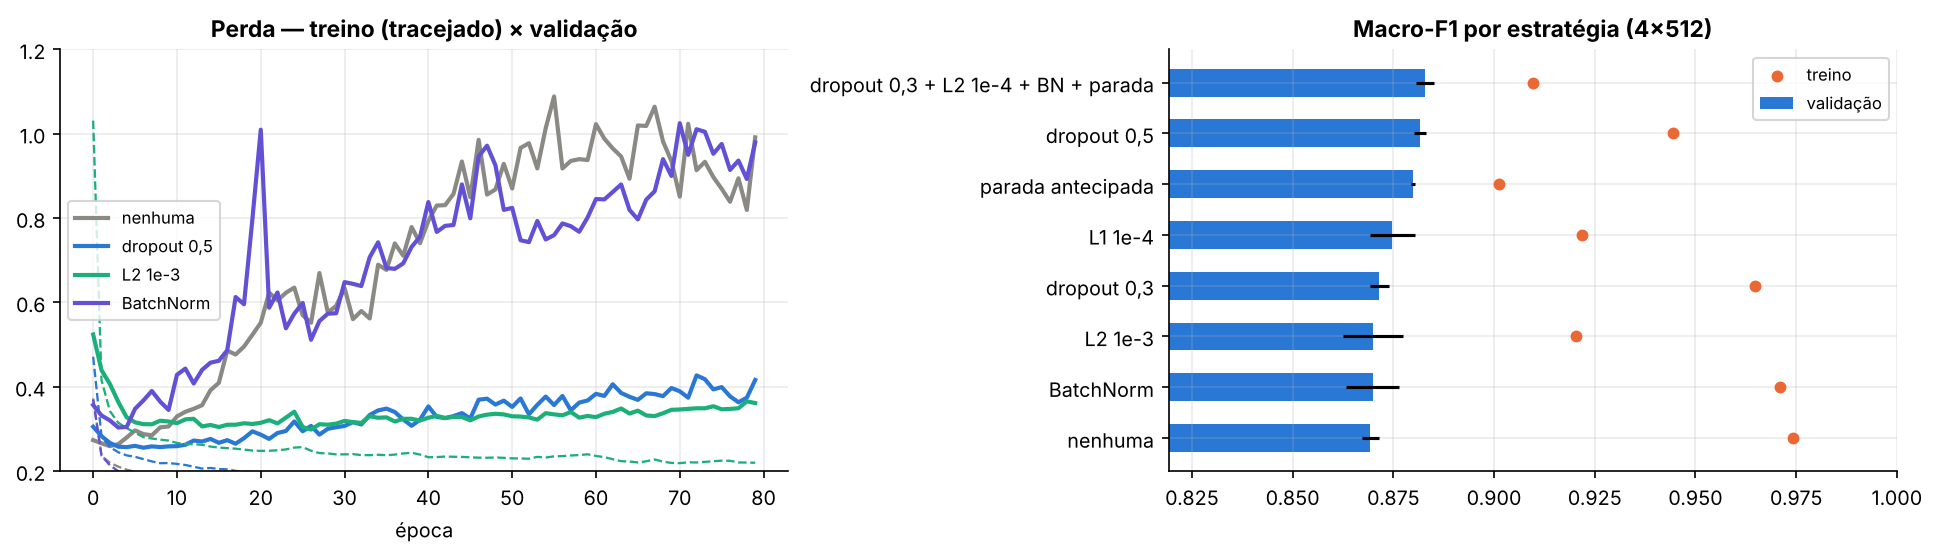

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sel = [("nenhuma", C_CINZA), ("dropout 0,5", C_AZUL), ("L2 1e-3", C_VERDE), ("BatchNorm", "#6250d6")]
for nome, cor in sel:
    h = hist_reg[nome]
    axes[0].plot(h["loss"], color=cor, lw=1.1, ls="--"); axes[0].plot(h["val_loss"], color=cor, lw=2, label=nome)
axes[0].set_ylim(0.2, 1.2); axes[0].set_title("Perda — treino (tracejado) × validação"); axes[0].set_xlabel("época"); axes[0].legend(fontsize=8)
t = tab_reg.sort_values("val_f1")
axes[1].barh(t.index, t["val_f1"], xerr=t["val_f1_dp"], color=C_AZUL, height=.55, label="validação")
axes[1].scatter(t["treino_f1"], t.index, color=C_LARANJA, zorder=3, s=22, label="treino")
axes[1].set_xlim(t["val_f1"].min() - .05, 1.0); axes[1].set_title("Macro-F1 por estratégia (4×512)"); axes[1].legend(fontsize=8)
salvar(fig, "08_regularizacao")

## 12. Experimento 4 — três arquiteturas promissoras

Selecionamos três configurações com perfis distintos de capacidade/custo:
* **A — Melhor Optuna:** a configuração de maior Macro-F1 na busca.
* **B — Compacta:** a tentativa com **menos parâmetros** entre as que ficaram a até 0,5 p.p. da melhor (eficiência).
* **C — Profunda regularizada:** 4×512 com dropout + L2 + BatchNorm + parada antecipada (melhor combinação do Exp. 3), representando a abordagem "grande e regularizada".

Cada uma é treinada com **5 sementes** para estimar a variância; a seleção final usa a média de Macro-F1 na validação.

In [23]:
def cfg_de_params(p):
    return {k: p[k] for k in ["n_layers", "units", "shape", "activation", "dropout", "l2", "batchnorm",
                              "lr", "batch_size", "patience"]}

cand = completas[completas["value"] >= estudo.best_value - 0.005].sort_values("n_params")
idx_b = int(cand.iloc[0]["number"])
if idx_b == estudo.best_trial.number and len(cand) > 1:
    idx_b = int(cand.iloc[1]["number"])
arquiteturas = {
    "A — Melhor Optuna": cfg_de_params(estudo.best_params),
    "B — Compacta": cfg_de_params(estudo.trials[idx_b].params),
    "C — Profunda regularizada": {"n_layers": 4, "units": 512, "shape": "constante", "activation": "relu",
                                  "dropout": 0.3, "l2": 1e-4, "batchnorm": True, "lr": lr_b,
                                  "batch_size": bs_b, "patience": 10},
}
for k, v in arquiteturas.items(): print(k, v)
json.dump(arquiteturas, open(f"{RES_DIR}/arquiteturas.json", "w"), indent=2, default=str)

A — Melhor Optuna {'n_layers': 2, 'units': 32, 'shape': 'constante', 'activation': 'relu', 'dropout': 0.2611160690210018, 'l2': 2.381895375882678e-05, 'batchnorm': True, 'lr': 0.0023513644034690584, 'batch_size': 512, 'patience': 20}
B — Compacta {'n_layers': 1, 'units': 32, 'shape': 'constante', 'activation': 'relu', 'dropout': 0.3780313550060566, 'l2': 4.85278156784125e-06, 'batchnorm': True, 'lr': 0.001631343633437024, 'batch_size': 512, 'patience': 20}
C — Profunda regularizada {'n_layers': 4, 'units': 512, 'shape': 'constante', 'activation': 'relu', 'dropout': 0.3, 'l2': 0.0001, 'batchnorm': True, 'lr': 0.0023513644034690584, 'batch_size': 512, 'patience': 10}


In [24]:
N_SEM = 5
res_arq, modelos_arq, hist_arq, pva_arq = [], {}, {}, {}
for nome, cfg in arquiteturas.items():
    for s in range(N_SEM):
        m, h, info = treinar(cfg, Xtr, ytr, Xva, yva, seed=SEED + s)
        linha, p_va = avaliar(m, info, nome, {"semente": s})
        res_arq.append(linha)
        if s == 0:
            modelos_arq[nome], hist_arq[nome], pva_arq[nome] = m, h, p_va
res_arq = pd.DataFrame(res_arq); res_arq.to_csv(f"{RES_DIR}/exp4_arquiteturas_sementes.csv", index=False)
tab_arq = res_arq.groupby("config", sort=False).agg(
    val_macro_f1=("val_macro_f1", "mean"), dp=("val_macro_f1", "std"), val_auc=("val_auc", "mean"),
    val_acuracia=("val_acuracia", "mean"), treino_macro_f1=("treino_macro_f1", "mean"), gap=("gap_f1", "mean"),
    n_params=("n_params", "first"), epocas=("epocas", "mean"), tempo_treino_s=("tempo_treino_s", "mean"),
    inferencia_us=("inferencia_us_amostra", "mean"))
display(tab_arq.round(4)); tab_arq.to_csv(f"{RES_DIR}/exp4_arquiteturas_resumo.csv")
ESCOLHIDA = tab_arq["val_macro_f1"].idxmax()
print("Arquitetura selecionada pela validação:", ESCOLHIDA)

,val_macro_f1,dp,val_auc,val_acuracia,treino_macro_f1,gap,n_params,epocas,tempo_treino_s,inferencia_us
config,,,,,,,,,,
A — Melhor Optuna,0.8832,0.0030,0.9600,0.8834,0.9018,0.0186,11329,28.8,14.4419,13.2578
B — Compacta,0.8842,0.0015,0.9599,0.8842,0.9050,0.0208,10177,33.2,14.7243,12.8439
C — Profunda regularizada,0.8818,0.0037,0.9594,0.8822,0.9097,0.0279,955393,26.6,80.9145,33.5686


Arquitetura selecionada pela validação: B — Compacta


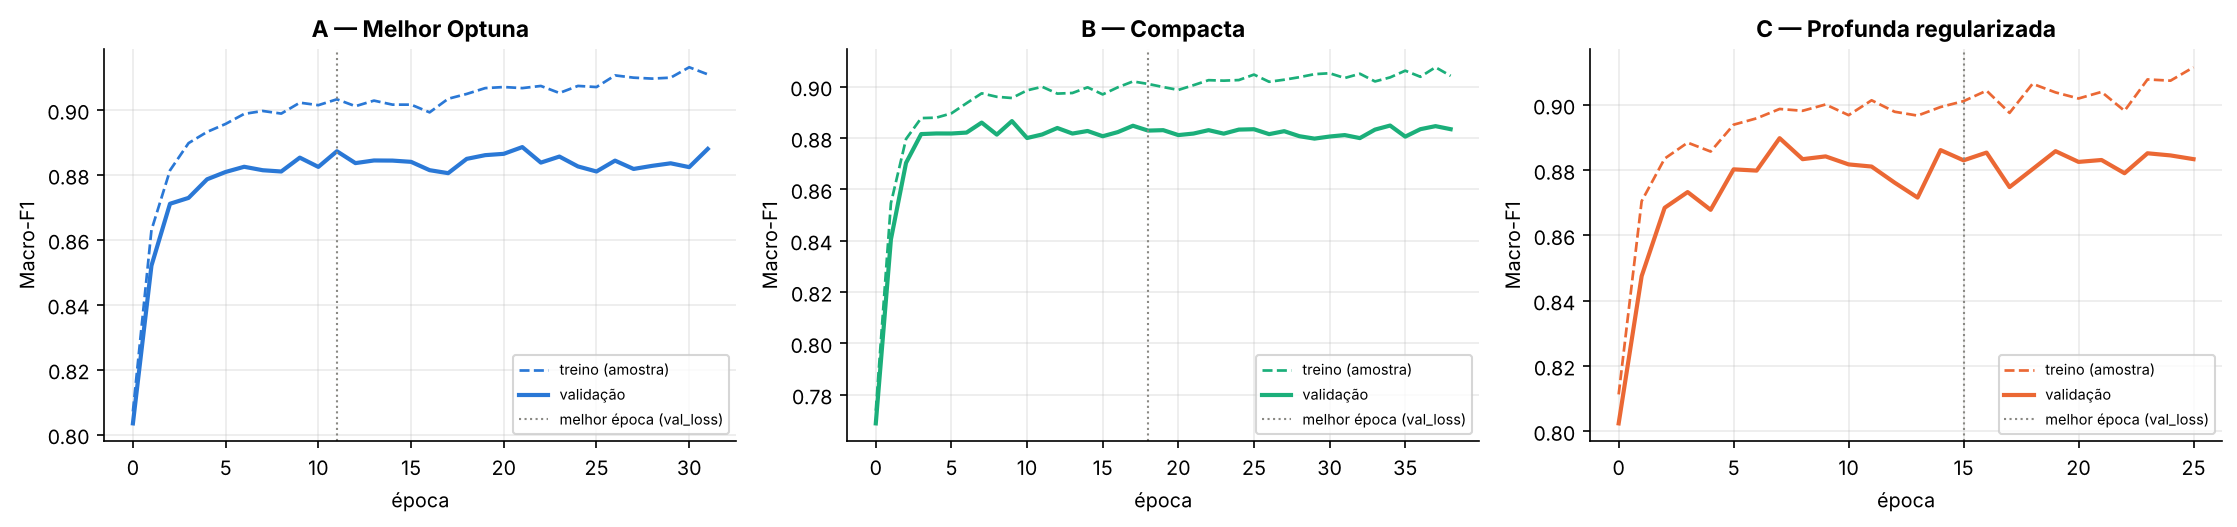

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, (nome, h), cor in zip(axes, hist_arq.items(), [C_AZUL, C_VERDE, C_LARANJA]):
    ax2 = ax
    ax2.plot(h["f1_tr"], color=cor, ls="--", lw=1.3, label="treino (amostra)")
    ax2.plot(h["f1_va"], color=cor, lw=2, label="validação")
    ax2.axvline(int(np.argmin(h["val_loss"])), color=C_CINZA, ls=":", lw=1, label="melhor época (val_loss)")
    ax2.set_title(nome); ax2.set_xlabel("época"); ax2.set_ylabel("Macro-F1"); ax2.legend(fontsize=7)
salvar(fig, "09_curvas_arquiteturas")

## 13. Avaliação final no conjunto de teste

1. **Limiar de decisão:** para cada modelo, escolhemos na **validação** o limiar que maximiza a Macro-F1 (varredura 0,2–0,8). O teste não participa dessa escolha.
2. Treinamos cada arquitetura (semente 0, já treinada acima) e avaliamos **uma única vez** no teste, junto com os modelos de referência.

In [26]:
def melhor_limiar(y, p):
    grade = np.arange(0.2, 0.81, 0.01)
    f = [f1_score(y, (p >= t).astype(int), average="macro") for t in grade]
    return float(grade[int(np.argmax(f))])

final = []
probs_te = {}
for nome, m in modelos_arq.items():
    lim = melhor_limiar(yva, pva_arq[nome])
    p_te, t_inf = prever(m, Xte); probs_te[nome] = p_te
    final.append({"modelo": "MLP " + nome, "limiar": lim, **metricas(yte, p_te, lim),
                  "macro_f1_limiar_0.5": metricas(yte, p_te)["macro_f1"],
                  "n_params": m.count_params(),
                  "tempo_treino_s": tab_arq.loc[nome, "tempo_treino_s"], "inferencia_us_amostra": t_inf})
for nome, m in ref_fit.items():
    p_va = m.predict_proba(Xva)[:, 1]; lim = melhor_limiar(yva, p_va) if nome != "Classe majoritária" else 0.5
    t0 = time.perf_counter(); p_te = m.predict_proba(Xte)[:, 1]; t_inf = (time.perf_counter() - t0) / len(Xte) * 1e6
    probs_te[nome] = p_te
    final.append({"modelo": nome, "limiar": lim, **metricas(yte, p_te, lim),
                  "macro_f1_limiar_0.5": metricas(yte, p_te)["macro_f1"],
                  "tempo_treino_s": ref_res.query("modelo == @nome")["tempo_treino_s"].iloc[0],
                  "inferencia_us_amostra": t_inf})
final = pd.DataFrame(final); final.to_csv(f"{RES_DIR}/teste_final.csv", index=False)
display(final.round(4))

,modelo,limiar,macro_f1,acuracia,precisao,revocacao,f1_classe1,auc,log_loss,macro_f1_limiar_0.5,n_params,tempo_treino_s,inferencia_us_amostra
0,MLP A — Melhor Optuna,0.49,0.8907,0.8907,0.8725,0.9062,0.8890,0.9654,0.2368,0.8899,11329.0,14.4419,22.7065
1,MLP B — Compacta,0.51,0.8902,0.8903,0.8788,0.8966,0.8876,0.9648,0.2388,0.8901,10177.0,14.7243,17.3579
2,MLP C — Profunda regularizada,0.48,0.8844,0.8845,0.8809,0.8799,0.8804,0.9616,0.2502,0.8823,955393.0,80.9145,34.4991
3,Classe majoritária,0.50,0.3407,0.5169,0.0000,0.0000,0.0000,0.5000,7.7872,0.3407,NaN,0.0013,0.0107
4,Regressão logística,0.45,0.8812,0.8812,0.8482,0.9186,0.8820,0.9514,0.2828,0.8775,NaN,3.4893,0.2899
5,Gradient boosting (HGB),0.44,0.8792,0.8793,0.8348,0.9354,0.8822,0.9623,0.2462,0.8797,NaN,3.7943,6.0899


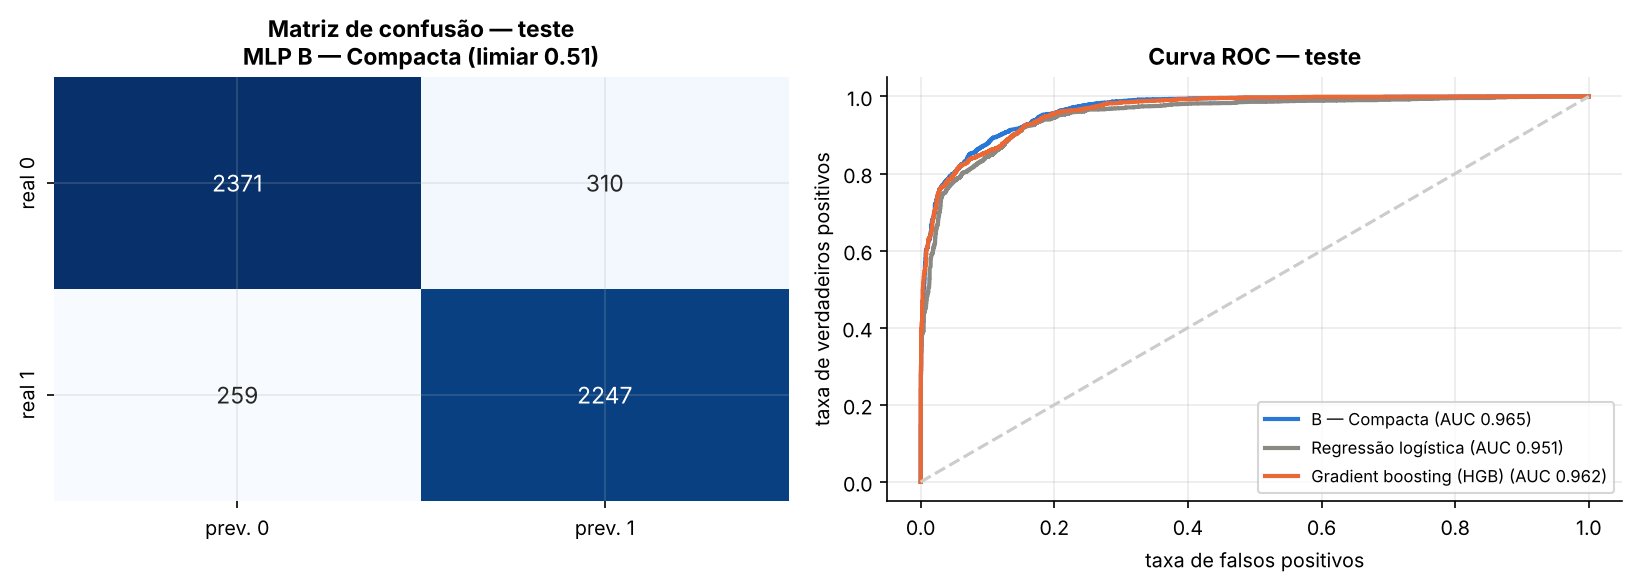

In [27]:
nome_mlp = ESCOLHIDA
lim = final.loc[final.modelo == "MLP " + nome_mlp, "limiar"].iloc[0]
cm = confusion_matrix(yte, (probs_te[nome_mlp] >= lim).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["prev. 0", "prev. 1"], yticklabels=["real 0", "real 1"], annot_kws={"fontsize": 11})
axes[0].set_title(f"Matriz de confusão — teste\nMLP {nome_mlp} (limiar {lim:.2f})")
for nome, cor in [(nome_mlp, C_AZUL), ("Regressão logística", C_CINZA), ("Gradient boosting (HGB)", C_LARANJA)]:
    fpr, tpr, _ = roc_curve(yte, probs_te[nome])
    axes[1].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(yte, probs_te[nome]):.3f})")
axes[1].plot([0, 1], [0, 1], color="#cccccc", ls="--"); axes[1].set_xlabel("taxa de falsos positivos")
axes[1].set_ylabel("taxa de verdadeiros positivos"); axes[1].set_title("Curva ROC — teste"); axes[1].legend(fontsize=8)
salvar(fig, "10_teste_confusao_roc")
np.save(f"{RES_DIR}/matriz_confusao_teste.npy", cm)

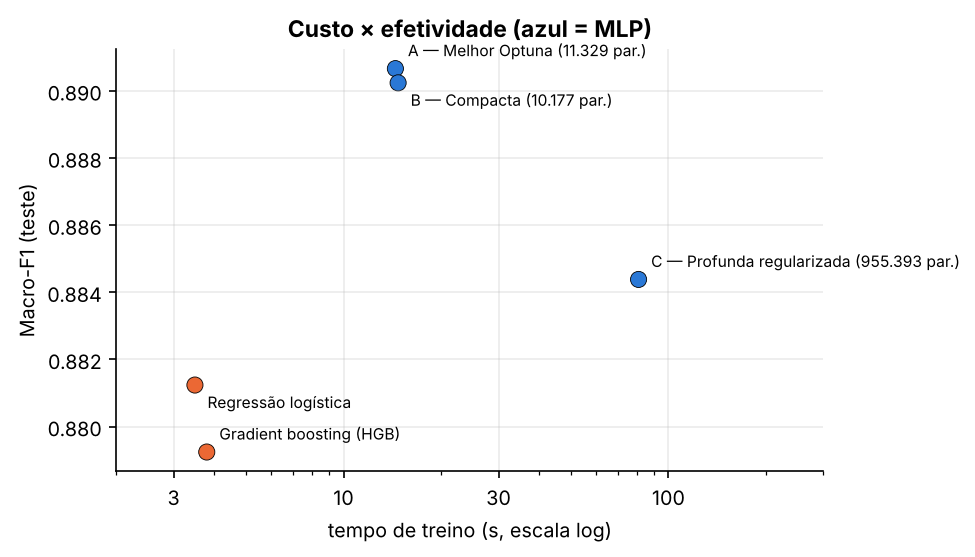

In [28]:
# custo × efetividade
fig, ax = plt.subplots(figsize=(6.5, 3.8))
f = final[final.modelo != "Classe majoritária"]
cores = [C_AZUL if m.startswith("MLP") else C_LARANJA for m in f.modelo]
ax.scatter(f["tempo_treino_s"], f["macro_f1"], s=60, c=cores, edgecolor="k", linewidth=.4)
for k, (_, r) in enumerate(f.iterrows()):
    dy = 6 if k % 2 == 0 else -11
    ax.annotate(f'{r["modelo"].replace("MLP ", "")} ({int(r["n_params"]):,} par.)'.replace(",", ".") if r["modelo"].startswith("MLP")
                else r["modelo"], (r["tempo_treino_s"], r["macro_f1"]), fontsize=7.5, xytext=(6, dy), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlim(2, 300); ax.set_xticks([3, 10, 30, 100])
ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("tempo de treino (s, escala log)"); ax.set_ylabel("Macro-F1 (teste)")
ax.set_title("Custo × efetividade (azul = MLP)")
salvar(fig, "11_custo_efetividade")

## 14. Análises complementares

### 14.1 Sensibilidade à estratégia de divisão
Repetimos o treino da arquitetura selecionada com uma divisão **aleatória estratificada** (sem agrupar por município), nas mesmas proporções. A diferença mostra quanto do desempenho viria de "reconhecer" municípios já vistos no treino.

In [29]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=len(idx_te), random_state=SEED)
r_trval, r_te = next(sss.split(X_all, y_all))
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=len(idx_va), random_state=SEED)
r_tr_rel, r_va_rel = next(sss2.split(X_all.iloc[r_trval], y_all[r_trval]))
r_tr, r_va = r_trval[r_tr_rel], r_trval[r_va_rel]
pp_r = make_preproc("log+std").fit(X_all.iloc[r_tr])
A, B, C_ = [pp_r.transform(X_all.iloc[i]).astype("float32") for i in (r_tr, r_va, r_te)]
sens = []
for s in range(3):
    m, h, info = treinar(arquiteturas[ESCOLHIDA], A, y_all[r_tr], B, y_all[r_va], seed=SEED + s, acompanhar_f1=False)
    lim_r = melhor_limiar(y_all[r_va], prever(m, B)[0])
    sens.append({"divisão": "aleatória (registros)", **metricas(y_all[r_te], prever(m, C_)[0], lim_r)})
    m, h, info = treinar(arquiteturas[ESCOLHIDA], Xtr, ytr, Xva, yva, seed=SEED + s, acompanhar_f1=False)
    lim_g = melhor_limiar(yva, prever(m, Xva)[0])
    sens.append({"divisão": "agrupada (municípios)", **metricas(yte, prever(m, Xte)[0], lim_g)})
sens = pd.DataFrame(sens)
tab_sens = sens.groupby("divisão")[["macro_f1", "auc", "acuracia"]].agg(["mean", "std"]).round(4)
display(tab_sens); sens.to_csv(f"{RES_DIR}/sensibilidade_divisao.csv", index=False)

macro_f1             auc         acuracia        
                          mean     std    mean     std     mean     std
divisão                                                                
agrupada (municípios)   0.8872  0.0047  0.9642  0.0007   0.8872  0.0047
aleatória (registros)   0.8890  0.0015  0.9640  0.0001   0.8894  0.0014

### 14.2 Desempenho por subgrupo no teste

In [30]:
te_df = df.iloc[idx_te].copy()
te_df["pred"] = (probs_te[ESCOLHIDA] >= lim).astype(int)
def f1_grupo(g):
    return pd.Series({"n": len(g), "taxa_real": g["executada"].mean(), "acuracia": (g["pred"] == g["executada"]).mean(),
                      "macro_f1": f1_score(g["executada"], g["pred"], average="macro") if g["executada"].nunique() > 1 else np.nan})
por_tipo = te_df.groupby("Tipo de Emenda").apply(f1_grupo); por_reg = te_df.groupby("Região").apply(f1_grupo)
display(por_tipo.round(3)); display(por_reg.round(3))
por_tipo.to_csv(f"{RES_DIR}/teste_por_tipo.csv"); por_reg.to_csv(f"{RES_DIR}/teste_por_regiao.csv")

,n,taxa_real,acuracia,macro_f1
Tipo de Emenda,,,,
Emenda Individual - Transferências Especiais,200.0,1.000,1.000,NaN
Emenda Individual - Transferências com Finalidade Definida,4054.0,0.479,0.879,0.879
Emenda de Bancada,205.0,0.434,0.946,0.946
Emenda de Comissão,244.0,0.197,0.869,0.778
Emenda de Relator,484.0,0.467,0.926,0.925


,n,taxa_real,acuracia,macro_f1
Região,,,,
Centro-Oeste,370.0,0.435,0.897,0.896
Nordeste,1768.0,0.470,0.875,0.875
Norte,568.0,0.574,0.891,0.889
Sudeste,1656.0,0.520,0.886,0.886
Sul,825.0,0.396,0.927,0.924


### 14.3 Importância por permutação (atributos originais, teste)
Embaralhamos cada coluna original (antes do pré-processamento) e medimos a queda de AUC no teste (média de 3 repetições). Isso indica em que informação a rede se apoia.

Código Programa                        0.1809
Código Plano Orçamentário              0.1559
Código Ação                            0.0468
Código Subfunção                       0.0148
Tipo de Emenda                         0.0071
Código Função                          0.0042
populacao_estimada                     0.0037
docentes_ensino_medio                  0.0033
Código UF IBGE                         0.0031
pessoal_ocupado                        0.0022
populacao_censo                        0.0021
receitas_brutas_realizadas             0.0020
estabelecimentos_ensino_fundamental    0.0016
area_urbanizada_km2                    0.0015
densidade_demografica                  0.0013
dtype: float64

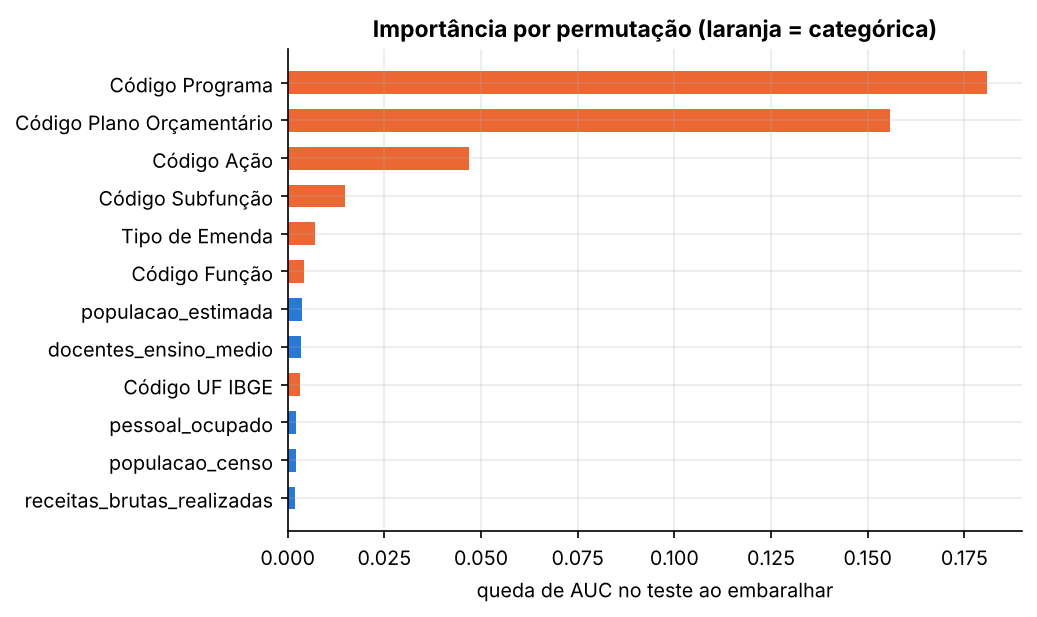

In [31]:
modelo_final = modelos_arq[ESCOLHIDA]
auc_base = roc_auc_score(yte, probs_te[ESCOLHIDA])
rng = np.random.default_rng(SEED); imp_perm = {}
for c in NUM_COLS + CAT_COLS:
    quedas = []
    for _ in range(3):
        Xp = Xte_raw.copy(); Xp[c] = rng.permutation(Xp[c].values)
        p = modelo_final.predict(preproc.transform(Xp).astype("float32"), batch_size=4096, verbose=0).ravel()
        quedas.append(auc_base - roc_auc_score(yte, p))
    imp_perm[c] = np.mean(quedas)
imp_perm = pd.Series(imp_perm).sort_values(ascending=False); imp_perm.to_csv(f"{RES_DIR}/importancia_permutacao.csv")
fig, ax = plt.subplots(figsize=(7, 4.2))
top = imp_perm.head(12)[::-1]
ax.barh(top.index, top.values, color=[C_LARANJA if c in CAT_COLS else C_AZUL for c in top.index], height=.6)
ax.set_xlabel("queda de AUC no teste ao embaralhar"); ax.set_title("Importância por permutação (laranja = categórica)")
salvar(fig, "12_importancia_permutacao")
display(imp_perm.head(15).round(4))

### 14.4 Ablação por grupo de atributos (regressão logística, validação)
Para confirmar a leitura da importância por permutação, treinamos regressões logísticas só com os atributos da emenda (classificação orçamentária) e só com os atributos da localidade (indicadores municipais, UF, região, bioma).

In [ ]:
def ablacao(cols_num, cols_cat):
    tr = []
    if cols_num: tr.append(("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), cols_num))
    if cols_cat: tr.append(("c", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), cols_cat))
    ct = ColumnTransformer(tr).fit(Xtr_raw)
    m = LogisticRegression(max_iter=3000).fit(ct.transform(Xtr_raw), ytr)
    p = m.predict_proba(ct.transform(Xva_raw))[:, 1]
    return {"auc_val": roc_auc_score(yva, p), "macro_f1_val": metricas(yva, p)["macro_f1"]}
ORC = ["Tipo de Emenda", "Código Função", "Código Subfunção", "Código Programa", "Código Ação", "Código Plano Orçamentário"]
LOC = ["Região", "bioma", "sistema_costeiro_marinho", "Código UF IBGE"]
tab_abl = pd.DataFrame({"todos os atributos": ablacao(NUM_COLS, CAT_COLS),
                        "só classificação orçamentária": ablacao([], ORC),
                        "só localidade (municipais + UF/região/bioma)": ablacao(NUM_COLS, LOC)}).T
display(tab_abl.round(4)); tab_abl.to_csv(f"{RES_DIR}/ablacao_grupos.csv")

                                              auc_val  macro_f1_val
todos os atributos                             0.9451        0.8708
só classificação orçamentária                  0.9462        0.8771
só localidade (municipais + UF/região/bioma)   0.6519        0.6228


### 14.5 Resumo consolidado

In [32]:
resumo = {
    "n_registros": len(df), "n_municipios": int(df["codigo_ibge"].nunique()), "taxa_executada": float(y_all.mean()),
    "dim_entrada": int(N_FEAT), "n_trials": N_TRIALS, "tempo_busca_min": t_busca / 60,
    "trials_completos": int((tent.state == "COMPLETE").sum()), "trials_podados": int((tent.state == "PRUNED").sum()),
    "melhor_val_optuna": estudo.best_value, "melhores_params": estudo.best_params, "escolhida": ESCOLHIDA,
}
json.dump(resumo, open(f"{RES_DIR}/resumo.json", "w"), indent=2, default=str)
print(json.dumps(resumo, indent=2, default=str))

{
  "n_registros": 36229,
  "n_municipios": 5416,
  "taxa_executada": 0.483010847663474,
  "dim_entrada": 313,
  "n_trials": 40,
  "tempo_busca_min": 25.060176423616667,
  "trials_completos": 26,
  "trials_podados": 14,
  "melhor_val_optuna": 0.887284391154517,
  "melhores_params": {
    "n_layers": 2,
    "units": 32,
    "shape": "constante",
    "activation": "relu",
    "dropout": 0.2611160690210018,
    "l2": 2.381895375882678e-05,
    "batchnorm": true,
    "lr": 0.0023513644034690584,
    "batch_size": 512,
    "patience": 20
  },
  "escolhida": "B \u2014 Compacta"
}
